# Adidas US sales: data audit, market segmentation and margin drivers

Invoice-level sales of Adidas products through six US retailers (2020–2021). The project

1. audits the data and fixes a revenue error that affects 40% of the rows,
2. segments the city–product markets with K-means, and
3. predicts the **operating margin** of each sale out of time and explains what drives it.

All reusable code lives in [`src/adidas`](../src/adidas); this notebook tells the story.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

from adidas import data, model, segmentation  # noqa: E402  (sets Windows env vars first)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance

FIGURES = ROOT / "reports" / "figures"
pd.set_option("display.precision", 3)
sns.set_theme(style="white", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})

## 1. Data audit

[Adidas US Sales Dataset](https://www.kaggle.com/datasets/heemalichaudhari/adidas-sales-dataset)
(Kaggle), downloaded with `kagglehub`. Each row is an invoice line: retailer, location,
product, price per unit, units sold, total sales, operating profit, operating margin and
sales channel.

A basic consistency check: total sales should equal price × units.

In [2]:
raw = data.load_raw()
print(f"{len(raw):,} invoice lines | {raw['Retailer'].nunique()} retailers | "
      f"{raw['City'].nunique()} cities | {raw['Product'].nunique()} products | "
      f"{raw['Invoice Date'].min():%b %Y} - {raw['Invoice Date'].max():%b %Y}")

audit = data.audit_reported_sales(raw)
pd.crosstab(raw["Sales Method"], audit, margins=True, margins_name="Total")

9,648 invoice lines | 6 retailers | 52 cities | 6 products | Jan 2020 - Dec 2021


reported sales equal,10 x price x units,other,price x units,Total
Sales Method,,,,
In-store,1740,0,0,1740
Online,1001,2,3886,4889
Outlet,1145,2,1872,3019
Total,3886,4,5758,9648


**40% of the rows (3,886) report total sales of exactly ten times price × units**:
every in-store sale and about a fifth of online and outlet sales. Operating profit equals
reported sales × margin, so it carries the same factor.

The error sits in the sales figure, not in the units: within the same channel, the affected
rows have *more* units than the rest (median 450 vs 113 online), not ten times fewer. The
fix rebuilds **revenue = price × units** and **profit = revenue × margin**. The operating
margin is a ratio and is not affected.

The affected rows also look different: larger, rounder deals with lower margins (median
35% vs 49% online). They may come from a different source system, which matters when
reading the model in section 4.

In [3]:
df = data.clean(raw)

by_channel = df.groupby("sales_method")[["reported_sales", "revenue"]].sum()
share = (by_channel / by_channel.sum()).add_suffix(" share")
totals = pd.DataFrame({"reported": [df["reported_sales"].sum(), df["reported_profit"].sum()],
                       "rebuilt": [df["revenue"].sum(), df["profit"].sum()]},
                      index=["total sales ($M)", "operating profit ($M)"]) / 1e6
display(totals.round(1))
share

,reported,rebuilt
total sales ($M),899.9,120.2
operating profit ($M),332.1,47.2


,reported_sales share,revenue share
sales_method,,
In-store,0.396,0.297
Online,0.275,0.374
Outlet,0.328,0.329


The reported figures overstate revenue about 7.5 times and, more importantly
for any analysis, **distort the channel mix**: in-store looks like the largest channel
(40% of sales) but is the smallest (30%), and online is actually the largest (37%).

## 2. Where the margin comes from

Average operating margin by channel and product (2020–2021, rebuilt figures).

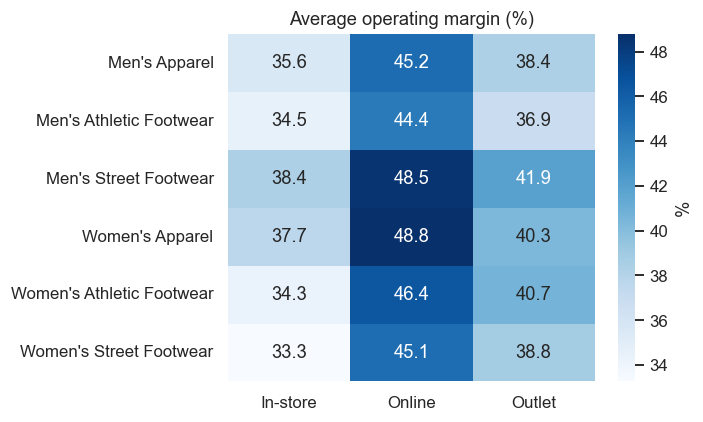

In [4]:
pivot = df.pivot_table(index="product", columns="sales_method",
                       values="operating_margin", aggfunc="mean")
fig, ax = plt.subplots(figsize=(6.5, 4))
sns.heatmap(100 * pivot, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "%"}, ax=ax)
ax.set(title="Average operating margin (%)", xlabel="", ylabel="")
ax.tick_params(axis="y", rotation=0)
fig.tight_layout()
fig.savefig(FIGURES / "margin_by_channel_product.png", dpi=150, bbox_inches="tight")

In [5]:
by_period = df.groupby(df["date"].dt.year).agg(
    invoice_lines=("revenue", "size"), retailers=("retailer", "nunique"),
    cities=("city", "nunique"), revenue_M=("revenue", lambda s: s.sum() / 1e6))
by_period

,invoice_lines,retailers,cities,revenue_M
date,,,,
2020,1302,5,9,24.237
2021,8346,6,45,95.929


Online sales carry the highest margins and in-store the lowest; products matter less
than channel. Coverage is very uneven over time: 2020 has nine cities and 2021 adds most
of the network, so the models are evaluated on the **last quarter of 2021**, which looks
like the bulk of the data, and trained on everything before it.

## 3. Market segmentation

Each **city–product market** is described by its average price, average units per invoice
line (deal size), average margin, share of online sales and total revenue (log). The
segmentation is fitted on the training period only (January 2020 – September 2021) so the
segment can later be used as a model feature without looking at the test quarter.

The number of clusters is chosen with the silhouette score.

In [6]:
train, test = model.time_split(df)
profiles = segmentation.market_profiles(df[train])
silhouette = segmentation.silhouette_by_k(profiles)
print(f"{len(profiles)} markets in the training period")
silhouette.to_frame().T

311 markets in the training period


k,2,3,4,5,6,7,8
silhouette,0.252,0.24,0.253,0.222,0.235,0.228,0.245


In [7]:
K = int(silhouette.idxmax())
segmenter = segmentation.fit_segments(profiles, K)
profiles["segment"] = segmenter.predict(profiles[segmentation.FEATURES])

summary = profiles.groupby("segment").agg(
    markets=("avg_price", "size"), avg_price=("avg_price", "mean"),
    avg_units=("avg_units", "mean"), avg_margin=("avg_margin", "mean"),
    online_share=("online_share", "mean"), revenue_share=("revenue", "sum"))
summary["revenue_share"] /= summary["revenue_share"].sum()
print(f"K = {K} (silhouette {silhouette[K]:.3f})")
summary

K = 4 (silhouette 0.253)


,markets,avg_price,avg_units,avg_margin,online_share,revenue_share
segment,,,,,,
0,77,42.546,349.618,0.489,0.432,0.349
1,96,37.471,150.570,0.411,0.466,0.122
2,61,40.068,263.890,0.430,0.835,0.166
3,77,54.938,292.084,0.361,0.431,0.363


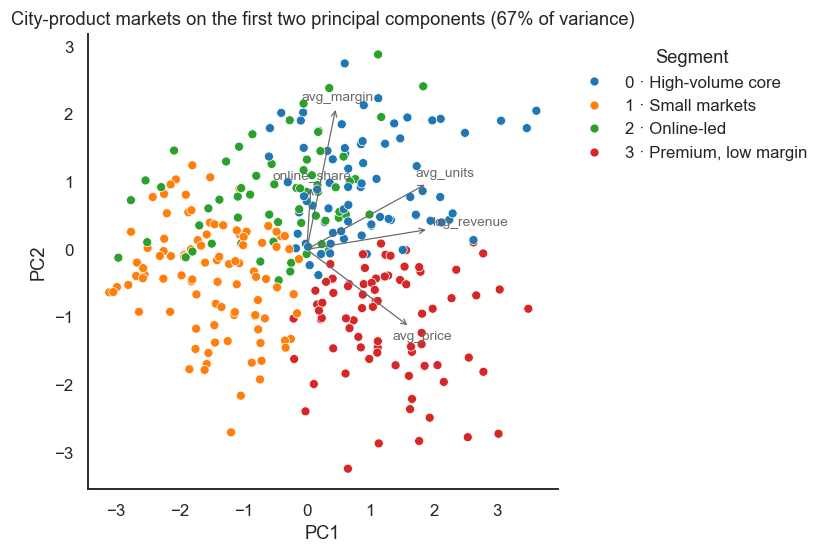

In [8]:
pca = PCA(2, random_state=0)
scaled = segmenter[:-1].transform(profiles[segmentation.FEATURES])
coords = pca.fit_transform(scaled)

SEGMENT_NAMES = {0: "0 · High-volume core", 1: "1 · Small markets",
                 2: "2 · Online-led", 3: "3 · Premium, low margin"}
fig, ax = plt.subplots(figsize=(7.5, 5.2))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=profiles["segment"].map(SEGMENT_NAMES),
                hue_order=[SEGMENT_NAMES[k] for k in sorted(SEGMENT_NAMES)],
                palette="tab10", s=35, ax=ax)
for j, name in enumerate(segmentation.FEATURES):  # loadings as arrows
    ax.annotate(name, xy=(0, 0), xytext=3 * pca.components_[:, j], color="dimgrey",
                fontsize=9, arrowprops=dict(arrowstyle="<-", color="dimgrey", lw=0.8))
ax.set(title=f"City-product markets on the first two principal components "
             f"({pca.explained_variance_ratio_.sum():.0%} of variance)",
       xlabel="PC1", ylabel="PC2")
ax.legend(title="Segment", frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
fig.savefig(FIGURES / "segments_pca.png", dpi=150, bbox_inches="tight")

Silhouette scores are low and flat (0.22–0.25): the markets form a continuum
rather than well-separated groups, so the segments are a useful summary, not natural
clusters. K = 4 has the highest score and gives readable profiles:

| Segment | Markets | Profile | Share of revenue |
|---|---:|---|---:|
| 0 · High-volume core | 77 | largest deals (350 units per line), highest margin (48.9%) | 35% |
| 3 · Premium, low margin | 77 | highest prices ($55), lowest margin (36.1%) | 36% |
| 2 · Online-led | 61 | 84% of sales online, margin 43.0% | 17% |
| 1 · Small markets | 96 | lowest prices and smallest deals, margin 41.1% | 12% |

Two segments with opposite economics generate 71% of revenue: the high-volume core earns
the best margins, while the premium-priced markets earn the worst, so higher prices do not
translate into higher margins.

## 4. Predicting the operating margin

**Why the margin and not the profit.** Operating profit is revenue × margin. A model that
predicts profit from sales figures mostly rediscovers that identity (and, with the
reported data, the 10× error). The margin is the part that has to be learned.

**Set-up.** Each invoice line is described by its channel, product, retailer, region,
state, city, price per unit, units and month. Training: January 2020 – September 2021;
test: October – December 2021, used once. Models:

* **Training mean** and **channel × product means**: simple business rules.
* **Ridge regression** on one-hot attributes: additive effects, no interactions.
* **Random forest**, with default settings and tuned with a randomized search over
  time-ordered folds of the training period.
* **Random forest + segment**: the tuned forest plus the market segment from section 3.

In [9]:
x_train, y_train = df[train], df.loc[train, "operating_margin"]
x_test, y_test = df[test], df.loc[test, "operating_margin"]
predictions = {}

predictions["Training mean"] = np.full(len(y_test), y_train.mean())
cell_means = df[train].groupby(["sales_method", "product"])["operating_margin"].mean()
predictions["Channel x product means"] = (
    x_test.set_index(["sales_method", "product"]).index.map(cell_means).to_numpy())

ridge = model.ridge().fit(x_train, y_train)
predictions["Ridge"] = ridge.predict(x_test)

forest = model.random_forest().fit(x_train, y_train)
predictions["Random forest"] = forest.predict(x_test)

search = model.tune_random_forest(x_train, y_train)
tuned = search.best_estimator_
predictions["Random forest, tuned"] = tuned.predict(x_test)
best = {k.split("__")[1]: v for k, v in search.best_params_.items()}
print("Tuned parameters:", best)

df["segment"] = segmentation.assign(df, profiles, segmenter)
with_segment = model.random_forest(model.CATEGORICAL + ["segment"], **best)
with_segment.fit(df[train], y_train)
predictions["Random forest, tuned + segment"] = with_segment.predict(df[test])

results = pd.DataFrame({name: model.scores(y_test, p) for name, p in predictions.items()}).T
print(f"Test: {test.sum():,} invoice lines, Oct-Dec 2021")
results.round(3)

Tuned parameters: {'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': None}


Test: 2,085 invoice lines, Oct-Dec 2021


,R2,MAE (pp),RMSE (pp)
Training mean,-0.001,7.295,9.078
Channel x product means,0.242,6.154,7.901
Ridge,0.489,5.017,6.487
Random forest,0.732,3.269,4.701
"Random forest, tuned",0.762,3.101,4.427
"Random forest, tuned + segment",0.755,3.028,4.494


,sales_method,product,units,region,state,city,retailer,price,month
drop in R2,0.504,0.349,0.226,0.151,0.109,0.105,0.037,0.025,0.001
std,0.013,0.008,0.004,0.004,0.003,0.003,0.004,0.002,0.001


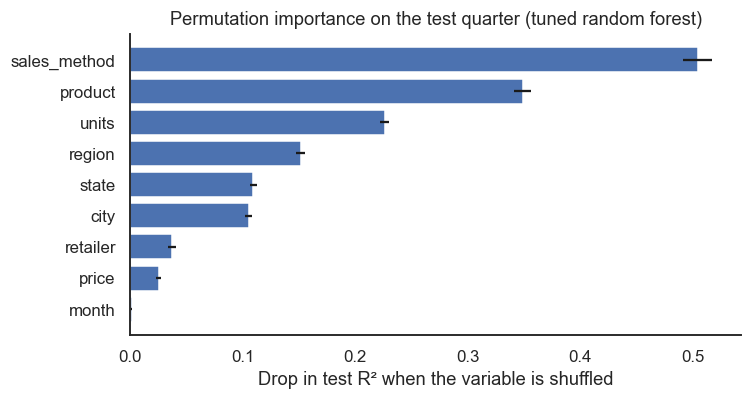

In [10]:
importance = permutation_importance(tuned, x_test[model.CATEGORICAL + model.NUMERIC], y_test,
                                    scoring="r2", n_repeats=10, random_state=0, n_jobs=1)
imp = (pd.DataFrame({"drop in R2": importance.importances_mean,
                     "std": importance.importances_std},
                    index=model.CATEGORICAL + model.NUMERIC)
       .sort_values("drop in R2"))

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(imp.index, imp["drop in R2"], xerr=imp["std"], color="#4C72B0")
ax.set(title="Permutation importance on the test quarter (tuned random forest)",
       xlabel="Drop in test R² when the variable is shuffled")
fig.tight_layout()
fig.savefig(FIGURES / "feature_importance.png", dpi=150, bbox_inches="tight")
imp.sort_values("drop in R2", ascending=False).round(3).T

* The tuned random forest explains **76% of the variance** of the margin in the
  unseen quarter, with a mean absolute error of **3.1 percentage points**, against 5.0 for
  ridge and 6.2 for channel × product averages.
* The gap between ridge (additive) and the forest shows that **margins depend on
  interactions**: the same product earns different margins depending on channel and
  location. Product alone explains little, but it becomes the second most important
  variable once it can interact with the rest.
* **Channel** is the main driver: shuffling it removes 0.50 of test R².
* Adding the market segment does not help (R² 0.755 vs 0.762): the forest already sees
  city and product, from which the segment is built. The original version of this project
  found a gain from the segment, but on a single random split of 63 markets.
* Part of the importance of **units** reflects the 10× rows found in the audit, which are
  larger deals with lower margins.

## Conclusions

* **Audit the data before modelling it.** 40% of the rows overstate sales tenfold.
  Fixing it changes total revenue ($120M, not $900M) and the channel mix: online, not
  in-store, is the largest channel.
* **Channel drives profitability.** Online sales earn the highest margins and in-store the
  lowest; within channels, margins depend on product × location combinations.
* **Segments summarize, they don't predict.** Four market segments with clear economics,
  but no predictive power beyond city and product.
* **Out-of-time accuracy.** A tuned random forest predicts the next quarter's margins with
  R² = 0.76 (MAE 3.1 pp), well above additive and rule-based baselines.

**Limitations.** A public dataset of unknown provenance; a single test quarter; the 10× fix
is supported by the data but cannot be checked against the source.

**Next steps.** Confirm the 10× rows with the data owner; shrinkage (hierarchical)
estimates for small markets; rolling-origin evaluation over several quarters.